# SUPERSTORE SALES ANALYSIS

### An Exploratory Data Analysis Project Using Python

## 1. Project Overview

This project focuses on analyzing Superstore sales data to understand customer purchasing behaviour, monthly sales trends, product category performance, regional profitability, and discount sensitivity.

The objective is to identify meaningful business insights and provide data-driven recommendations to improve business performance.

## 2. Business Objectives

- Analyze overall sales and profit performance.
- Identify monthly sales trends and seasonality.
- Evaluate category-wise sales and profitability.
- Compare regional sales and profit performance.
- Analyze customer segment purchasing behaviour.
- Understand the relationship between discounts and profitability.
- Develop actionable business recommendations.

## 3. Tools and Technologies

- Python
- Jupyter Notebook
- Pandas
- Matplotlib
- Seaborn

## 4. Dataset Description

The project uses the Superstore Sales dataset containing customer orders, product categories, sales, discounts, quantities, regions, and profits.

The original dataset contains 10,800 rows and 21 columns.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df = pd.read_excel("superstore_sales.csv.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,2017-08-11 00:00:00,2017-11-11 00:00:00,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,2017-12-06 00:00:00,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,2016-11-10 00:00:00,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [4]:
df.shape

(10800, 21)

In [5]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  str    
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       99

In [7]:
df.describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [8]:
df.isnull().sum()

Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

In [9]:
missing_values = df.isnull().sum()

print("MISSING VALUES IN OUR DATASET:")
print(missing_values[missing_values > 0])

MISSING VALUES IN OUR DATASET:
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64


In [10]:
df.loc[df["Order Date"].isna(), ["Row ID", "Order ID"]].head(10)

,Row ID,Order ID
9994,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South
9999,Returned,Order ID
10000,Yes,CA-2015-100762
10001,Yes,CA-2015-100762
10002,Yes,CA-2015-100762
10003,Yes,CA-2015-100762



## 5. Data Cleaning and Preparation

The following data-cleaning activities were performed:

1. Inspected the dataset structure and column information.
2. Identified 806 records with missing Order Date values.
3. Removed records without Order Date, resulting in 9,994 sales records.
4. Identified 11 missing Postal Code values and retained these records because postal codes were not required for the main analysis.
5. Checked for duplicate records and found zero exact duplicate rows.
6. Converted Order Date into a proper datetime format.
7. Extracted Year, Month, Month Name, and Year-Month columns for time-based analysis.

The cleaned dataset was stored in a separate DataFrame named `df_clean`.


In [11]:
df_clean = df.dropna(subset=["Order Date"]).copy()

In [12]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (10800, 21)
Cleaned dataset: (9994, 21)


In [13]:
df_clean.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [14]:
df_clean.duplicated().sum()

np.int64(0)

In [15]:
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"]
)

In [16]:
df_clean["Order Date"].dtype

dtype('<M8[us]')

In [17]:
df_clean["Order Date"].head()

0   2017-08-11
1   2017-08-11
2   2017-12-06
3   2016-11-10
4   2016-11-10
Name: Order Date, dtype: datetime64[us]

In [18]:
df_clean["Year"] = df_clean["Order Date"].dt.year

In [19]:
df_clean["Month"] = df_clean["Order Date"].dt.month

In [20]:
df_clean["Month Name"] = df_clean["Order Date"].dt.month_name()

In [21]:
df_clean["Year-Month"] = df_clean["Order Date"].dt.to_period("M").astype(str)

In [22]:
df_clean[["Order Date", "Year", "Month", "Month Name", "Year-Month"]].head(10)

,Order Date,Year,Month,Month Name,Year-Month
0,2017-08-11,2017,8,August,2017-08
1,2017-08-11,2017,8,August,2017-08
2,2017-12-06,2017,12,December,2017-12
3,2016-11-10,2016,11,November,2016-11
4,2016-11-10,2016,11,November,2016-11
5,2015-09-06,2015,9,September,2015-09
6,2015-09-06,2015,9,September,2015-09
7,2015-09-06,2015,9,September,2015-09
8,2015-09-06,2015,9,September,2015-09
9,2015-09-06,2015,9,September,2015-09



# 6. Exploratory Data Analysis

## 6.1 Overall Business Performance

Calculated the following key performance indicators:

- Total Sales
- Total Profit
- Total Quantity Sold
- Number of Unique Orders
- Overall Profit Margin

## 6.2 Monthly Sales Analysis

- Extracted Year, Month, Month Name and Year-Month from Order Date.
- Aggregated sales by month.
- Identified the highest and lowest sales months.
- Visualized monthly sales trends using a line chart.

## 6.3 Product Category Analysis

- Grouped Sales and Profit by product category.
- Identified the highest-revenue and highest-profit categories.
- Compared category-wise profitability.

## 6.4 Regional Analysis

- Aggregated Sales and Profit by region.
- Identified the best-performing region.
- Compared regional sales and profitability.

## 6.5 Customer Segment Analysis

- Analyzed Consumer, Corporate and Home Office segments.
- Compared Sales, Profit and Quantity.
- Identified the largest customer segment.

## 6.6 Discount Sensitivity Analysis

- Investigated the relationship between Discount and Profit.
- Created a scatter plot.
- Calculated profit at different discount levels.
- Identified discount groups associated with negative profit.

## 6.7 Correlation Analysis

- Calculated Pearson correlation coefficients.
- Created a correlation heatmap using Seaborn.
- Investigated relationships among Sales, Profit, Quantity and Discount.

## 6.8 Outlier Analysis

- Created Sales and Profit boxplots.
- Applied the Interquartile Range (IQR) method.
- Identified potential outliers.
- Retained unusual records pending business investigation.


In [23]:
monthly_sales = df_clean.groupby("Year-Month")["Sales"].sum().reset_index()

monthly_sales = monthly_sales.sort_values("Year-Month")

monthly_sales

,Year-Month,Sales
0,2015-01,28953.7060
1,2015-02,12743.1080
2,2015-03,54801.9060
3,2015-04,24710.0160
4,2015-05,29639.8340
5,2015-06,29287.0306
6,2015-07,35341.2460
7,2015-08,37854.5475
8,2015-09,66110.2238
9,2015-10,34561.9470


In [24]:
all_months = pd.period_range(
    start="2015-01",
    end="2018-12",
    freq="M"
)

available_months = pd.PeriodIndex(
    monthly_sales["Year-Month"],
    freq="M"
)

missing_months = all_months.difference(available_months)

print("Missing months:")
print(missing_months)

Missing months:
PeriodIndex([], dtype='period[M]')


In [25]:
print("Total monthly records:", len(monthly_sales))

print("Unique months:", monthly_sales["Year-Month"].nunique())

print("Duplicate months:", monthly_sales["Year-Month"].duplicated().sum())

Total monthly records: 48
Unique months: 48
Duplicate months: 0


In [26]:
monthly_sales["Month Start"] = pd.to_datetime(
    monthly_sales["Year-Month"]
)

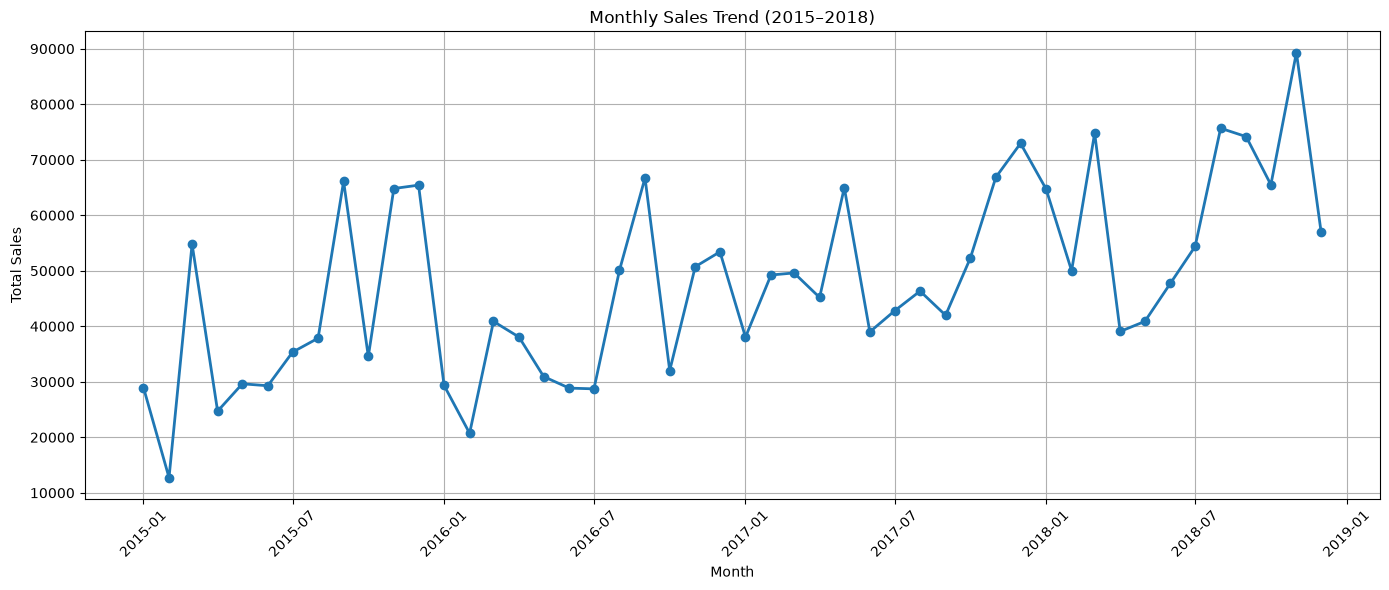

In [27]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["Month Start"],
    monthly_sales["Sales"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Trend (2015–2018)")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

In [28]:
highest_sales = monthly_sales.loc[
    monthly_sales["Sales"].idxmax()
]

print("HIGHEST SALES MONTH")
print(highest_sales)

HIGHEST SALES MONTH
Year-Month                 2018-11
Sales                     89306.24
Month Start    2018-11-01 00:00:00
Name: 46, dtype: object


In [29]:
lowest_sales = monthly_sales.loc[
    monthly_sales["Sales"].idxmin()
]

print("LOWEST SALES MONTH")
print(lowest_sales)

LOWEST SALES MONTH
Year-Month                 2015-02
Sales                    12743.108
Month Start    2015-02-01 00:00:00
Name: 1, dtype: object


### Monthly Seasonality Analysis

In [30]:

# Arrange months in calendar order

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

# Calculate total sales for each calendar month

seasonality_summary = (
    df_clean.groupby("Month Name")["Sales"]
    .sum()
    .reindex(month_order)
    .rename("Total Sales")
    .reset_index()
)

# Display monthly seasonality results

print(seasonality_summary.round(2))

# Find highest and lowest sales months

highest_seasonal_month = seasonality_summary.loc[
    seasonality_summary["Total Sales"].idxmax()
]

lowest_seasonal_month = seasonality_summary.loc[
    seasonality_summary["Total Sales"].idxmin()
]

print("\nHighest Combined Sales Month:")
print(highest_seasonal_month)

print("\nLowest Combined Sales Month:")
print(lowest_seasonal_month)


   Month Name  Total Sales
0     January    161083.59
1    February    132721.36
2       March    220064.65
3       April    147031.26
4         May    166420.32
5        June    144883.50
6        July    161227.10
7      August    209964.37
8   September    248989.30
9     October    184356.33
10   November    271693.75
11   December    248765.33

Highest Combined Sales Month:
Month Name        November
Total Sales    271693.7525
Name: 10, dtype: object

Lowest Combined Sales Month:
Month Name        February
Total Sales    132721.3594
Name: 1, dtype: object


In [31]:
print("HIGHEST SALES:")
print("Month:", highest_sales["Year-Month"])
print("Sales:", highest_sales["Sales"])

print("\nLOWEST SALES:")
print("Month:", lowest_sales["Year-Month"])
print("Sales:", lowest_sales["Sales"])

HIGHEST SALES:
Month: 2018-11
Sales: 89306.24

LOWEST SALES:
Month: 2015-02
Sales: 12743.108


In [32]:
category_summary = df_clean.groupby("Category")[["Sales", "Profit"]].sum().reset_index()

print(category_summary)

          Category        Sales       Profit
0        Furniture  741999.7953   18451.2728
1  Office Supplies  719047.0320  122490.8008
2       Technology  836154.0330  145454.9481


In [33]:
category_summary = category_summary.sort_values(
    by="Sales",
    ascending=False
)

print(category_summary)

          Category        Sales       Profit
2       Technology  836154.0330  145454.9481
0        Furniture  741999.7953   18451.2728
1  Office Supplies  719047.0320  122490.8008


In [34]:
best_profit = category_summary.loc[
    category_summary["Profit"].idxmax()
]

print(best_profit)

Category     Technology
Sales        836154.033
Profit      145454.9481
Name: 2, dtype: object


In [35]:
best_sales = category_summary.loc[
    category_summary["Sales"].idxmax()
]

print(best_sales)

Category     Technology
Sales        836154.033
Profit      145454.9481
Name: 2, dtype: object


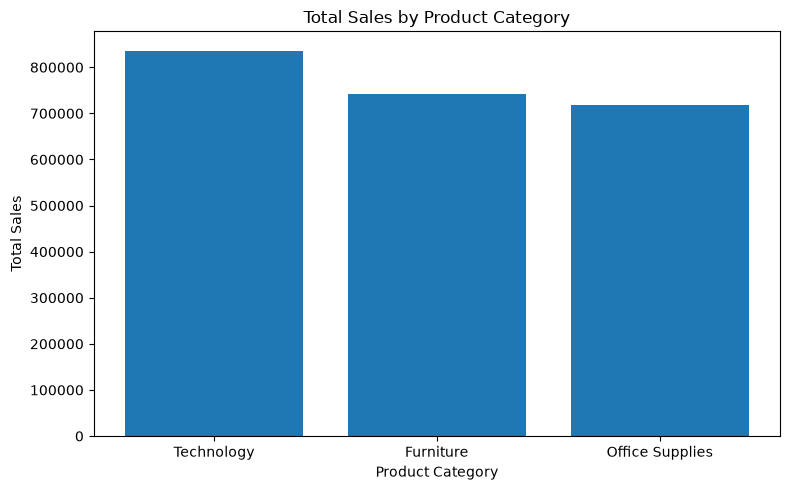

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_summary["Category"],
    category_summary["Sales"]
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

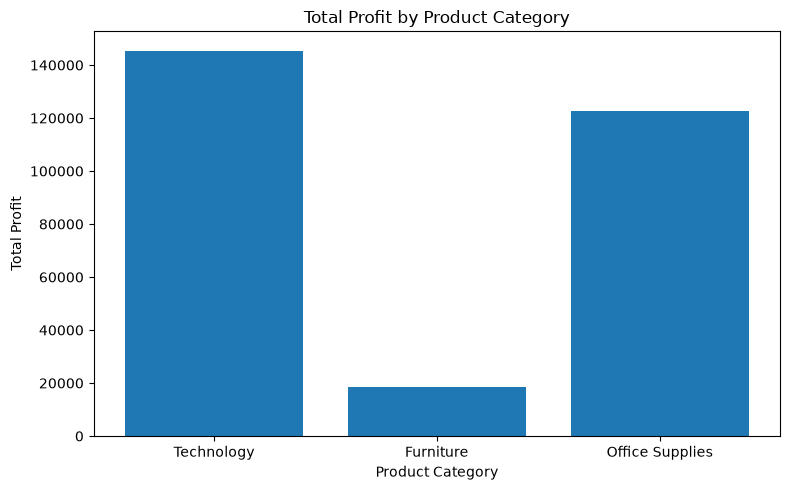

In [37]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_summary["Category"],
    category_summary["Profit"]
)

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

In [38]:
region_summary = df_clean.groupby("Region")[["Sales", "Profit"]].sum().reset_index()

print(region_summary)

    Region        Sales       Profit
0  Central  501239.8908   39706.3625
1     East  678781.2400   91522.7800
2    South  391721.9050   46749.4303
3     West  725457.8245  108418.4489


In [39]:
region_summary = region_summary.sort_values(
    by="Sales",
    ascending=False
)

print(region_summary)

    Region        Sales       Profit
3     West  725457.8245  108418.4489
1     East  678781.2400   91522.7800
0  Central  501239.8908   39706.3625
2    South  391721.9050   46749.4303


In [40]:
best_region = region_summary.loc[
    region_summary["Profit"].idxmax()
]

print(best_region)

Region           West
Sales     725457.8245
Profit    108418.4489
Name: 3, dtype: object


In [41]:
worst_region = region_summary.loc[
    region_summary["Profit"].idxmin()
]

print(worst_region)

Region        Central
Sales     501239.8908
Profit     39706.3625
Name: 0, dtype: object


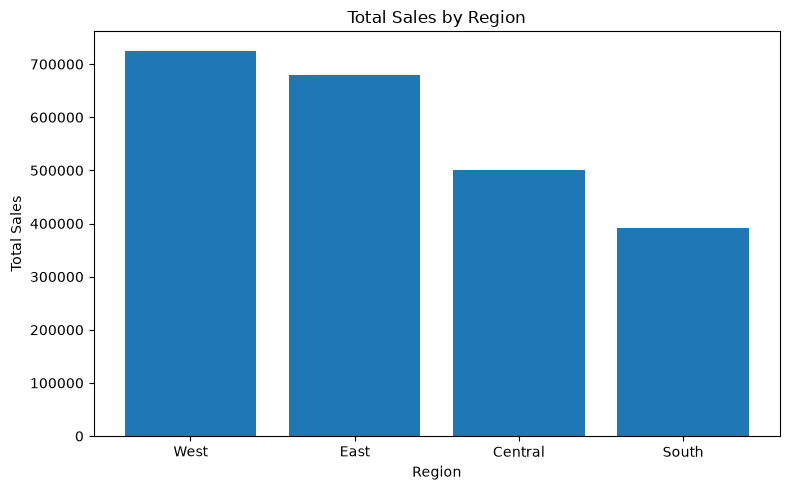

In [42]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_summary["Region"],
    region_summary["Sales"]
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

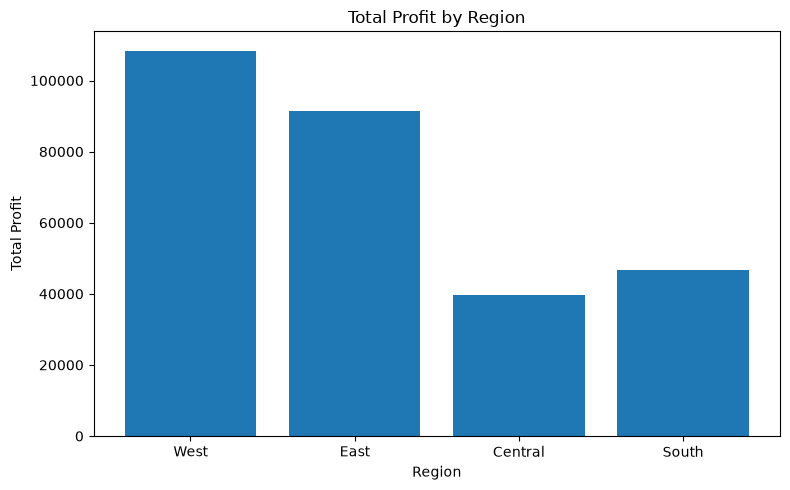

In [43]:
plt.figure(figsize=(8, 5))

plt.bar(
    region_summary["Region"],
    region_summary["Profit"]
)

plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

In [44]:
segment_summary = df_clean.groupby("Segment")[["Sales", "Profit", "Quantity"]].sum().reset_index()

print(segment_summary)

       Segment         Sales       Profit  Quantity
0     Consumer  1.161401e+06  134119.2092   19521.0
1    Corporate  7.061464e+05   91979.1340   11608.0
2  Home Office  4.296531e+05   60298.6785    6744.0


In [45]:
segment_summary = segment_summary.sort_values(
    by="Sales",
    ascending=False
)

print(segment_summary)

       Segment         Sales       Profit  Quantity
0     Consumer  1.161401e+06  134119.2092   19521.0
1    Corporate  7.061464e+05   91979.1340   11608.0
2  Home Office  4.296531e+05   60298.6785    6744.0


In [46]:
best_segment = segment_summary.loc[
    segment_summary["Profit"].idxmax()
]

print(best_segment)

Segment        Consumer
Sales       1161401.345
Profit      134119.2092
Quantity        19521.0
Name: 0, dtype: object


In [47]:
best_quantity_segment = segment_summary.loc[
    segment_summary["Quantity"].idxmax()
]

print(best_quantity_segment)

Segment        Consumer
Sales       1161401.345
Profit      134119.2092
Quantity        19521.0
Name: 0, dtype: object


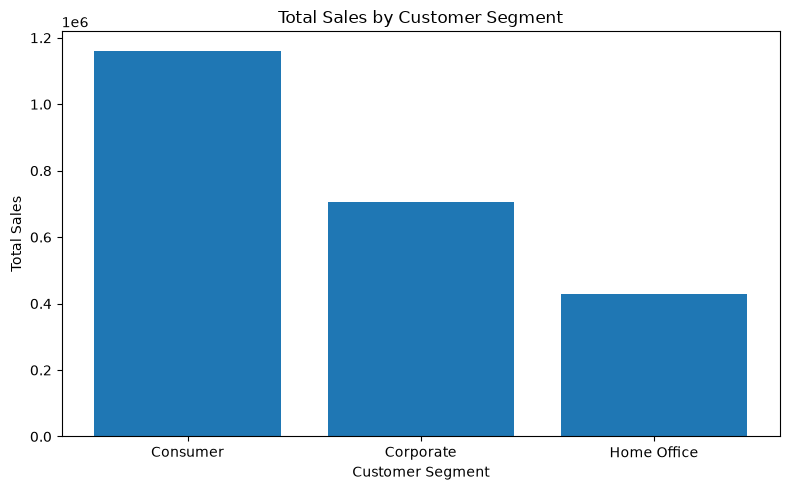

In [48]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Sales"]
)

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

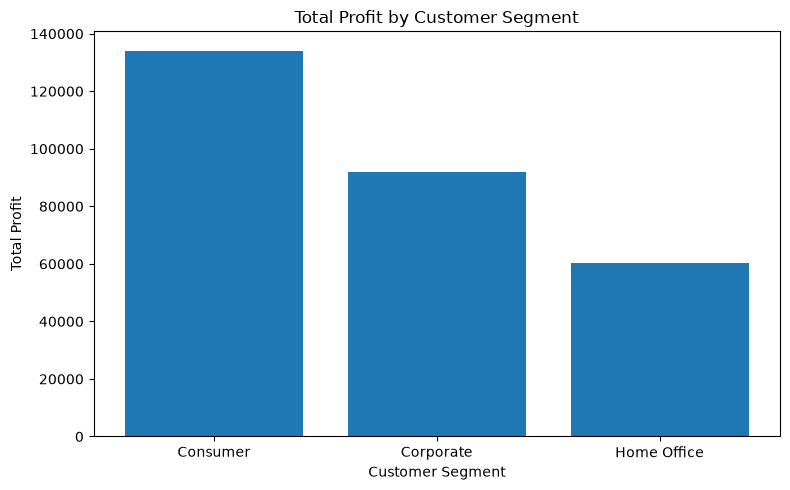

In [49]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Profit"]
)

plt.title("Total Profit by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show()

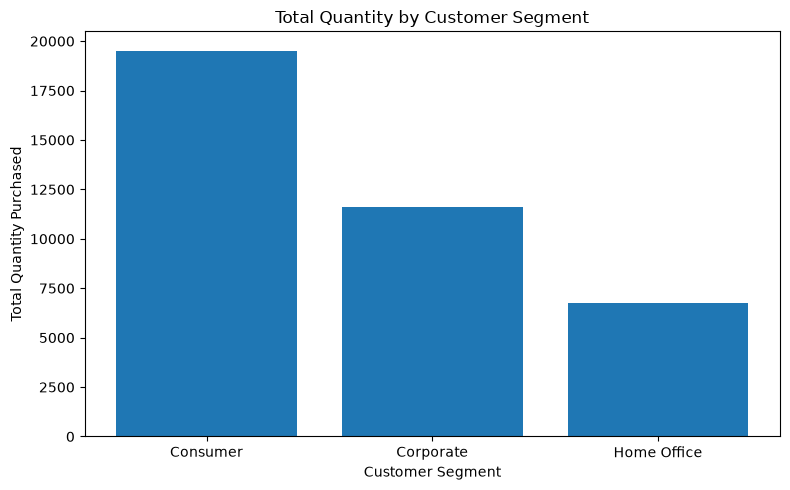

In [50]:
plt.figure(figsize=(8, 5))

plt.bar(
    segment_summary["Segment"],
    segment_summary["Quantity"]
)

plt.title("Total Quantity by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Quantity Purchased")

plt.tight_layout()
plt.show()

Records available for plotting: 9994


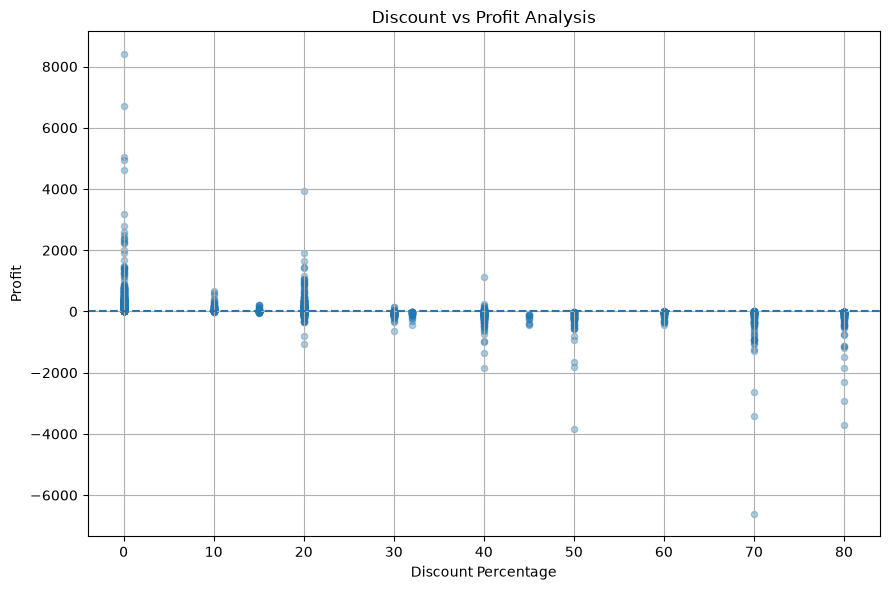

In [51]:
plot_data = df_clean[["Discount", "Profit"]].dropna()

print("Records available for plotting:", len(plot_data))

fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    plot_data["Discount"] * 100,
    plot_data["Profit"],
    alpha=0.35,
    s=20
)

ax.axhline(y=0, linestyle="--")

ax.set_title("Discount vs Profit Analysis")
ax.set_xlabel("Discount Percentage")
ax.set_ylabel("Profit")

ax.grid(True)
plt.tight_layout()
plt.show()

In [52]:
discount_summary = df_clean.groupby("Discount").agg(
    Number_of_Records=("Profit", "size"),
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean")
).reset_index()

discount_summary = discount_summary.sort_values("Discount")

print(discount_summary.round(2))

    Discount  Number_of_Records  Total_Sales  Total_Profit  Average_Profit
0       0.00               4798   1087908.47     320987.60           66.90
1       0.10                 94     54369.35       9029.18           96.06
2       0.15                 52     27558.52       1418.99           27.29
3       0.20               3657    764594.37      90337.31           24.70
4       0.30                227    103226.66     -10369.28          -45.68
5       0.32                 27     14493.46      -2391.14          -88.56
6       0.40                206    116417.78     -23057.05         -111.93
7       0.45                 11      5484.97      -2493.11         -226.65
8       0.50                 66     58918.54     -20506.43         -310.70
9       0.60                138      6644.70      -5944.66          -43.08
10      0.70                418     40620.28     -40075.36          -95.87
11      0.80                300     16963.76     -30539.04         -101.80


In [53]:

# Analyze transactions with discounts of 30% and above

high_discount_records = df_clean.loc[
    df_clean["Discount"] >= 0.30
]

# Calculate the number of records

high_discount_count = len(high_discount_records)

# Calculate total profit

high_discount_profit = high_discount_records["Profit"].sum()

# Display results

print("HIGH DISCOUNT ANALYSIS")

print("Number of Records:", high_discount_count)

print("Total Profit:", round(high_discount_profit, 2))


HIGH DISCOUNT ANALYSIS
Number of Records: 1393
Total Profit: -135376.06


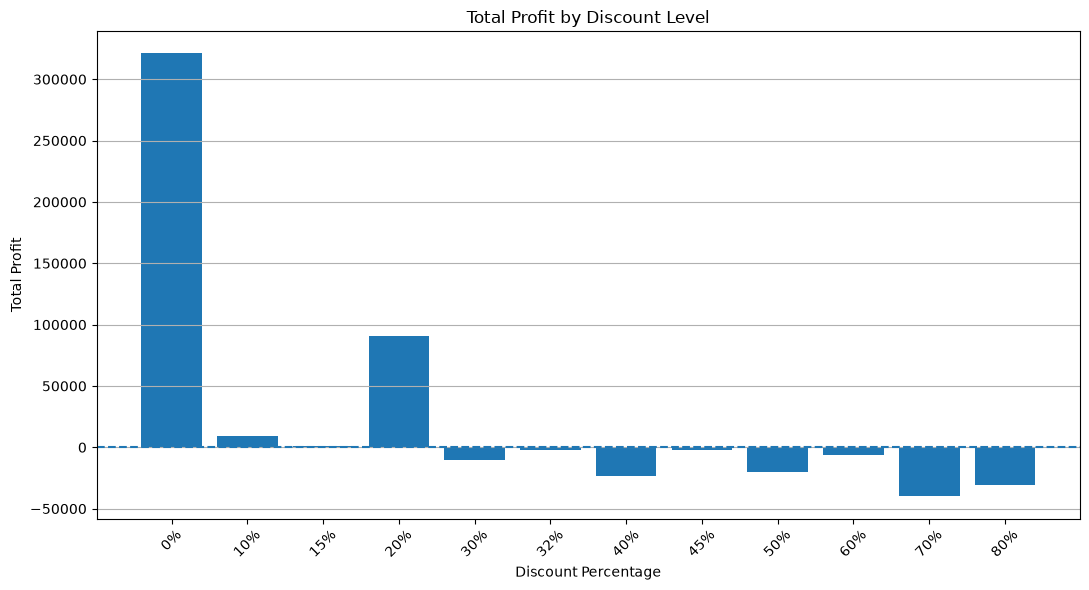

In [54]:
discount_summary["Discount_Label"] = (
    discount_summary["Discount"] * 100
).map(lambda x: f"{x:g}%")

plt.figure(figsize=(11, 6))

plt.bar(
    discount_summary["Discount_Label"],
    discount_summary["Total_Profit"]
)

plt.axhline(y=0, linestyle="--")

plt.title("Total Profit by Discount Level")
plt.xlabel("Discount Percentage")
plt.ylabel("Total Profit")

plt.xticks(rotation=45)

plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [55]:
total_sales = df_clean["Sales"].sum()

total_profit = df_clean["Profit"].sum()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 2297200.86
Total Profit: 286397.02
Profit Margin: 12.47 %


In [56]:
category_summary["Profit Margin (%)"] = (
    category_summary["Profit"] /
    category_summary["Sales"]
) * 100

print(
    category_summary[
        ["Category", "Sales", "Profit", "Profit Margin (%)"]
    ].round(2)
)

          Category      Sales     Profit  Profit Margin (%)
2       Technology  836154.03  145454.95              17.40
0        Furniture  741999.80   18451.27               2.49
1  Office Supplies  719047.03  122490.80              17.04


In [57]:
Q1 = df_clean["Sales"].quantile(0.25)

Q3 = df_clean["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 17.28
Q3: 209.94
IQR: 192.66
Lower Bound: -271.71000000000004
Upper Bound: 498.93


In [58]:
sales_outlier_mask = (
    (df_clean["Sales"] < lower_bound) |
    (df_clean["Sales"] > upper_bound)
)

print("Number of Sales Outliers:")
print(sales_outlier_mask.sum())

Number of Sales Outliers:
1167


In [59]:
Q1_profit = df_clean["Profit"].quantile(0.25)

Q3_profit = df_clean["Profit"].quantile(0.75)

IQR_profit = Q3_profit - Q1_profit

lower_profit = Q1_profit - 1.5 * IQR_profit

upper_profit = Q3_profit + 1.5 * IQR_profit

profit_outlier_mask = (
    (df_clean["Profit"] < lower_profit) |
    (df_clean["Profit"] > upper_profit)
)

print("Number of Profit Outliers:")
print(profit_outlier_mask.sum())

Number of Profit Outliers:
1881


In [60]:
total_records = len(df_clean)

sales_outlier_count = sales_outlier_mask.sum()

profit_outlier_count = profit_outlier_mask.sum()

sales_outlier_percentage = (
    sales_outlier_count / total_records
) * 100

profit_outlier_percentage = (
    profit_outlier_count / total_records
) * 100

print("Total Records:", total_records)

print("Sales Outliers:", sales_outlier_count)
print("Sales Outlier Percentage:", round(sales_outlier_percentage, 2), "%")

print("Profit Outliers:", profit_outlier_count)
print("Profit Outlier Percentage:", round(profit_outlier_percentage, 2), "%")

Total Records: 9994
Sales Outliers: 1167
Sales Outlier Percentage: 11.68 %
Profit Outliers: 1881
Profit Outlier Percentage: 18.82 %


In [61]:
sales_outliers = df_clean.loc[
    sales_outlier_mask,
    ["Order ID", "Category", "Sub-Category",
     "Region", "Sales", "Profit", "Discount"]
]

sales_outliers = sales_outliers.sort_values(
    by="Sales",
    ascending=False
)

print(sales_outliers.head(10))

            Order ID         Category Sub-Category   Region      Sales  \
2697  CA-2015-145317       Technology     Machines    South  22638.480   
6826  CA-2017-118689       Technology      Copiers  Central  17499.950   
8153  CA-2018-140151       Technology      Copiers     West  13999.960   
2623  CA-2018-127180       Technology      Copiers     East  11199.968   
4190  CA-2018-166709       Technology      Copiers     East  10499.970   
9039  CA-2017-117121  Office Supplies      Binders  Central   9892.740   
4098  CA-2015-116904  Office Supplies      Binders  Central   9449.950   
4277  US-2017-107440       Technology     Machines     East   9099.930   
8488  CA-2017-158841       Technology     Machines    South   8749.950   
6425  CA-2017-143714       Technology      Copiers     East   8399.976   

         Profit  Discount  
2697 -1811.0784       0.5  
6826  8399.9760       0.0  
8153  6719.9808       0.0  
2623  3919.9888       0.2  
4190  5039.9856       0.0  
9039  4946.3700  

In [62]:
profit_outliers = df_clean.loc[
    profit_outlier_mask,
    ["Order ID", "Category", "Sub-Category",
     "Region", "Sales", "Discount", "Profit"]
]

profit_outliers = profit_outliers.sort_values(
    by="Profit",
    ascending=True
)

print(profit_outliers.head(10))

            Order ID         Category Sub-Category   Region      Sales  \
7772  CA-2017-108196       Technology     Machines     East   4499.985   
683   US-2018-168116       Technology     Machines    South   7999.980   
9774  CA-2015-169019  Office Supplies      Binders  Central   2177.584   
3011  CA-2018-134845       Technology     Machines     West   2549.985   
4991  US-2018-122714  Office Supplies      Binders  Central   1889.990   
3151  CA-2016-147830       Technology     Machines     East   1799.994   
5310  CA-2018-131254  Office Supplies      Binders  Central   1525.188   
9639  CA-2016-116638        Furniture       Tables    South   4297.644   
1199  CA-2017-130946  Office Supplies      Binders  Central   1088.792   
2697  CA-2015-145317       Technology     Machines    South  22638.480   

      Discount     Profit  
7772       0.7 -6599.9780  
683        0.5 -3839.9904  
9774       0.8 -3701.8928  
3011       0.7 -3399.9800  
4991       0.8 -2929.4845  
3151       0.7 -2

In [76]:
total_sales = df_clean["Sales"].sum()

total_profit = df_clean["Profit"].sum()

total_quantity = df_clean["Quantity"].sum()

total_orders = df_clean["Order ID"].nunique()

profit_margin = (
    total_profit / total_sales
) * 100

print("FINAL BUSINESS PERFORMANCE")

print("Total Sales:", round(total_sales, 2))

print("Total Profit:", round(total_profit, 2))

print("Total Quantity:", total_quantity)

print("Unique Orders:", total_orders)

print("Profit Margin:", round(profit_margin, 2), "%")


FINAL BUSINESS PERFORMANCE
Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity: 37873.0
Unique Orders: 5009
Profit Margin: 12.47 %


# 7. Dashboard

Developed an interactive-style business dashboard using Matplotlib to present key Superstore performance indicators and sales insights.

The dashboard includes four visualizations:

- **Monthly Sales Trend:** Displays sales performance over time from 2015 to 2018.
- **Category-wise Sales:** Compares total sales across product categories.
- **Region-wise Profit:** Highlights profit contribution across different regions.
- **Customer Segment Sales:** Compares sales across Consumer, Corporate and Home Office segments.

Key performance indicators (KPIs) displayed:
- Total Sales
- Total Profit
- Overall Profit Margin

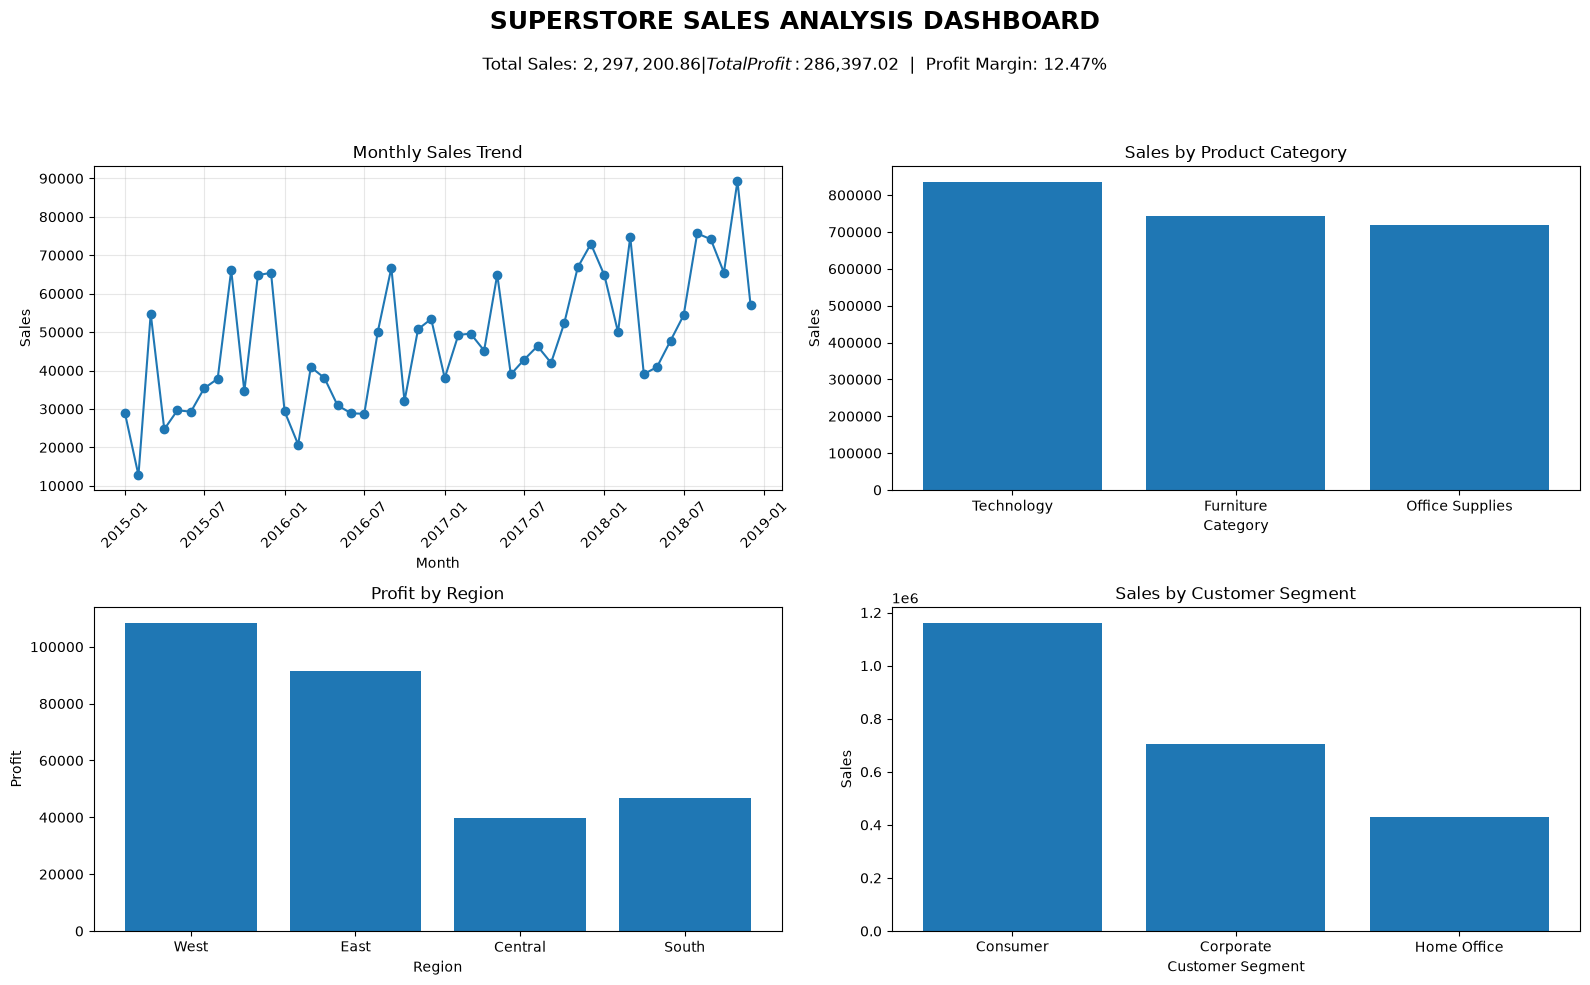

In [64]:

# Create a dashboard with 4 charts

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Main dashboard title

fig.suptitle(
    "SUPERSTORE SALES ANALYSIS DASHBOARD",
    fontsize=18,
    fontweight="bold"
)

# Display important business metrics

fig.text(
    0.5, 0.92,
    f"Total Sales: ${total_sales:,.2f}  |  "
    f"Total Profit: ${total_profit:,.2f}  |  "
    f"Profit Margin: {profit_margin:.2f}%",
    ha="center",
    fontsize=12
)

# CHART 1: Monthly Sales Trend

axes[0, 0].plot(
    monthly_sales["Month Start"],
    monthly_sales["Sales"],
    marker="o"
)

axes[0, 0].set_title("Monthly Sales Trend")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Sales")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True, alpha=0.3)


# CHART 2: Category-wise Sales

axes[0, 1].bar(
    category_summary["Category"],
    category_summary["Sales"]
)

axes[0, 1].set_title("Sales by Product Category")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Sales")


# CHART 3: Region-wise Profit

axes[1, 0].bar(
    region_summary["Region"],
    region_summary["Profit"]
)

axes[1, 0].set_title("Profit by Region")
axes[1, 0].set_xlabel("Region")
axes[1, 0].set_ylabel("Profit")


# CHART 4: Customer Segment Sales

axes[1, 1].bar(
    segment_summary["Segment"],
    segment_summary["Sales"]
)

axes[1, 1].set_title("Sales by Customer Segment")
axes[1, 1].set_xlabel("Customer Segment")
axes[1, 1].set_ylabel("Sales")


# Adjust dashboard spacing

plt.tight_layout(rect=[0, 0, 1, 0.90])

# Display the complete dashboard

plt.show()


# 8. Additional Data Visualizations

Created additional visualizations using Seaborn and Matplotlib to explore sales performance, relationships, distributions, and patterns within the Superstore dataset.

The visualizations include:

- **Category-wise Sales Analysis:** Compared total sales across Furniture, Office Supplies, and Technology to identify the highest-performing product category.
- **Discount vs. Profit by Product Category:** Examined the relationship between discount percentages and profit across different product categories to identify profitable and loss-making transactions.
- **Correlation Heatmap:** Visualized correlation coefficients between numerical variables such as Sales, Profit, Quantity, and Discount to understand their relationships.
- **Pairplot:** Explored pairwise relationships among Sales, Profit, Quantity, and Discount, with product categories distinguished by color and individual variable distributions displayed using histograms.
- **Sales Distribution and Outliers:** Used a boxplot to examine the distribution of Sales, including the median, spread, and potential outliers.

These visualizations provide additional insights into product category performance, discount impact, relationships between numerical variables, and sales distribution, supporting a better understanding of business performance and potential areas for improvement.

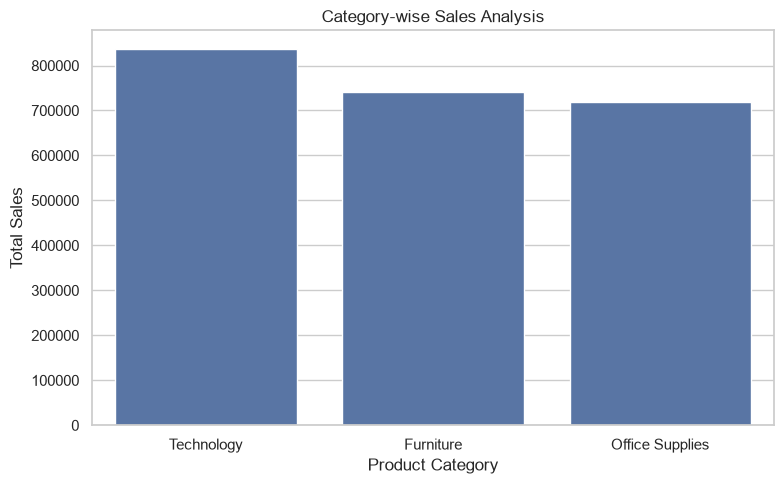

In [65]:
# Set chart style
sns.set_theme(style="whitegrid")

# Create chart
plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_summary,
    x="Category",
    y="Sales"
)

# Add title and labels
plt.title("Category-wise Sales Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

In [66]:
df_clean["Discount_Percent"] = df_clean["Discount"] * 100

print(df_clean[["Discount", "Discount_Percent", "Profit"]].head())

   Discount  Discount_Percent    Profit
0      0.00               0.0   41.9136
1      0.00               0.0  219.5820
2      0.00               0.0    6.8714
3      0.45              45.0 -383.0310
4      0.20              20.0    2.5164


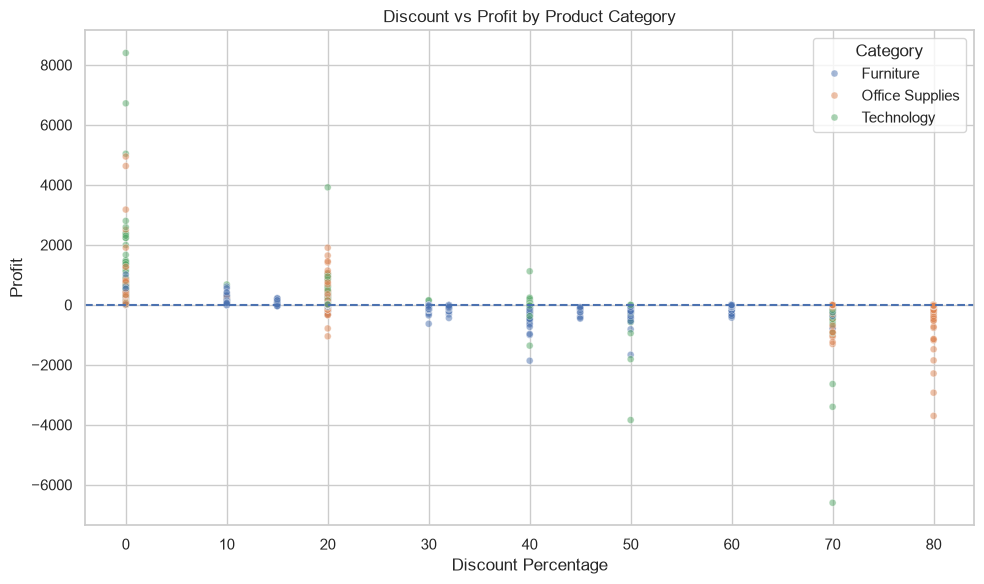

In [67]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="Discount_Percent",
    y="Profit",
    hue="Category",
    alpha=0.5,
    s=25
)

plt.axhline(y=0, linestyle="--")

plt.title("Discount vs Profit by Product Category")
plt.xlabel("Discount Percentage")
plt.ylabel("Profit")

plt.grid(True)
plt.tight_layout()

plt.show()

In [68]:
numeric_data = df_clean[
    ["Sales", "Profit", "Quantity", "Discount"]
]

print(numeric_data.head())

      Sales    Profit  Quantity  Discount
0  261.9600   41.9136       2.0      0.00
1  731.9400  219.5820       3.0      0.00
2   14.6200    6.8714       2.0      0.00
3  957.5775 -383.0310       5.0      0.45
4   22.3680    2.5164       2.0      0.20


In [69]:
correlation = numeric_data.corr()

print(correlation.round(2))

          Sales  Profit  Quantity  Discount
Sales      1.00    0.48      0.20     -0.03
Profit     0.48    1.00      0.07     -0.22
Quantity   0.20    0.07      1.00      0.01
Discount  -0.03   -0.22      0.01      1.00


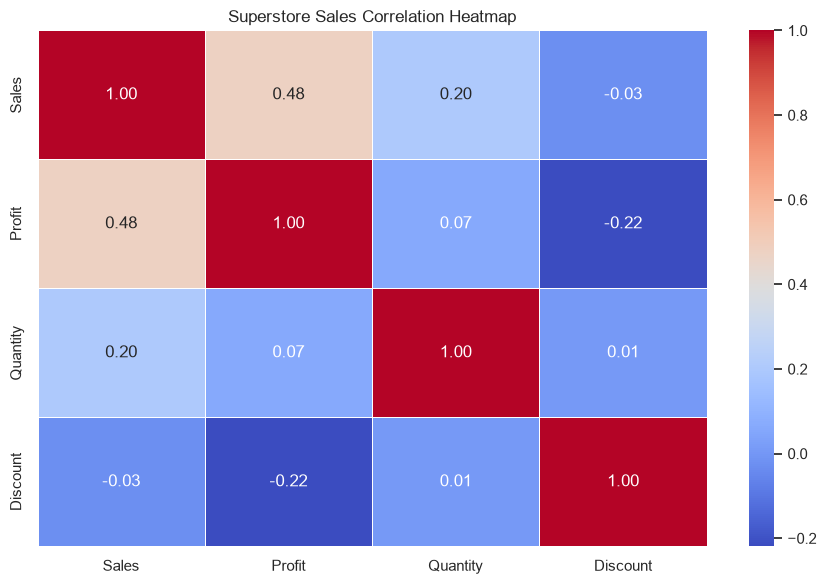

In [70]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Superstore Sales Correlation Heatmap")

plt.tight_layout()
plt.show()

In [71]:
print("Sales vs Profit:",
      round(correlation.loc["Sales", "Profit"], 2))

print("Discount vs Profit:",
      round(correlation.loc["Discount", "Profit"], 2))

print("Sales vs Quantity:",
      round(correlation.loc["Sales", "Quantity"], 2))

print("Sales vs Discount:",
      round(correlation.loc["Sales", "Discount"], 2))

Sales vs Profit: 0.48
Discount vs Profit: -0.22
Sales vs Quantity: 0.2
Sales vs Discount: -0.03


In [72]:
pairplot_data = df_clean[
    ["Sales", "Profit", "Quantity", "Discount", "Category"]
].dropna()

print(pairplot_data.head())

      Sales    Profit  Quantity  Discount         Category
0  261.9600   41.9136       2.0      0.00        Furniture
1  731.9400  219.5820       3.0      0.00        Furniture
2   14.6200    6.8714       2.0      0.00  Office Supplies
3  957.5775 -383.0310       5.0      0.45        Furniture
4   22.3680    2.5164       2.0      0.20  Office Supplies


In [73]:
pairplot_data = pairplot_data.sample(
    n=min(1000, len(pairplot_data)),
    random_state=42
)

print("Records selected:", len(pairplot_data))

Records selected: 1000


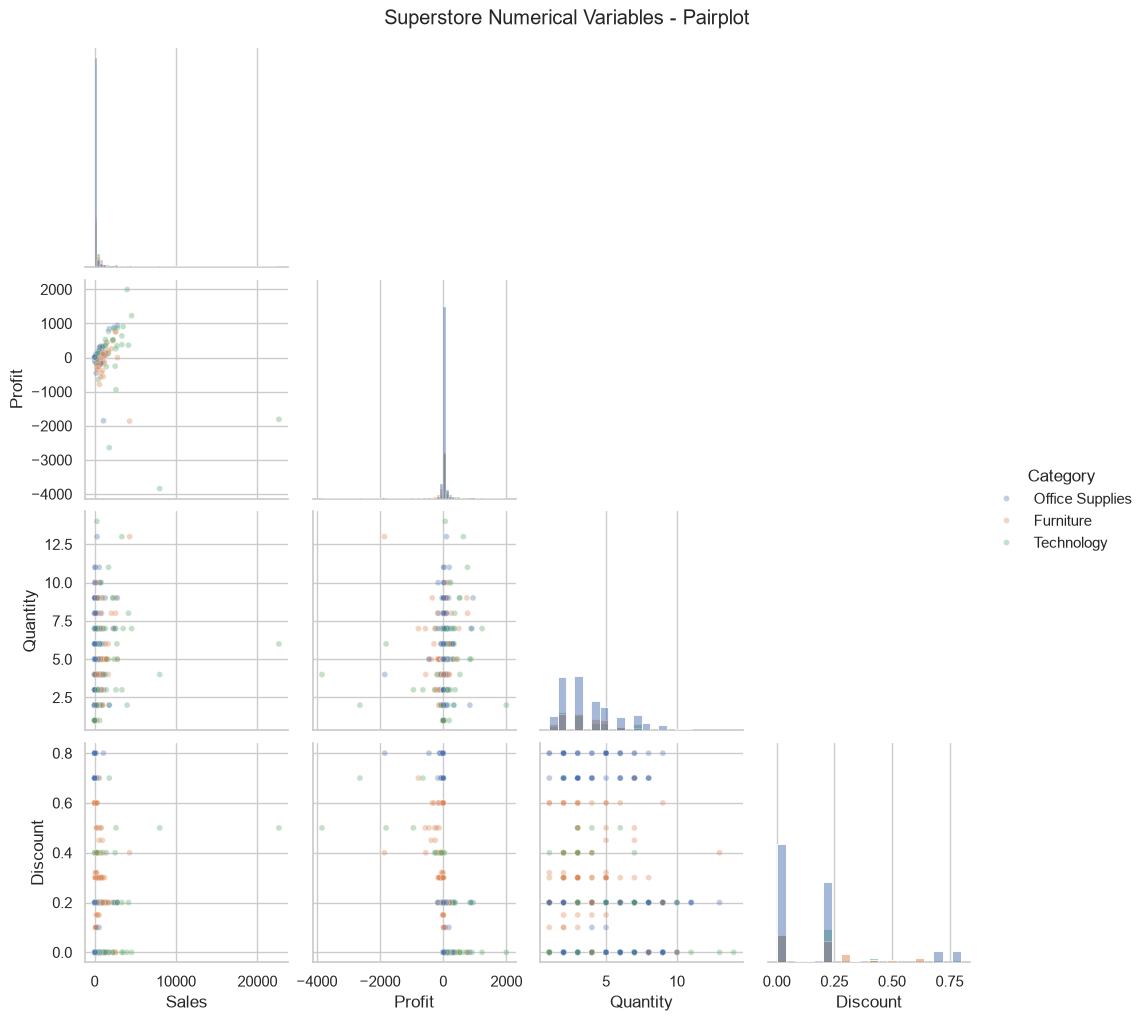

In [74]:
pair_grid = sns.pairplot(
    data=pairplot_data,
    vars=["Sales", "Profit", "Quantity", "Discount"],
    hue="Category",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 18}
)

pair_grid.fig.suptitle(
    "Superstore Numerical Variables - Pairplot",
    y=1.02
)

plt.show()

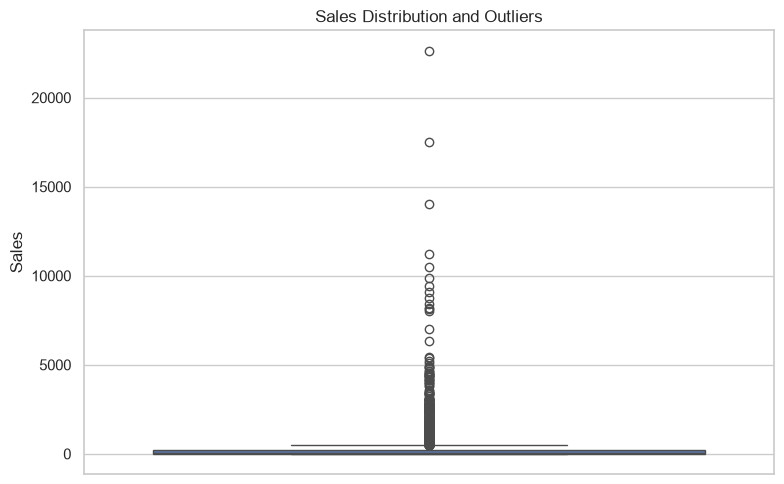

In [75]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    y="Sales"
)

plt.title("Sales Distribution and Outliers")
plt.ylabel("Sales")

plt.tight_layout()
plt.show()

# 9. Executive Business Takeaways

### 1. Overall Performance
The Superstore generated $2,297,200.86 in sales and $286,397.02 in profit, achieving an overall profit margin of 12.47%.

### 2. Product Category Performance
Technology was the strongest product category, generating the highest sales and profit. Furniture recorded a relatively low profit margin of approximately 2.49%.

### 3. Regional Performance
The West region generated the highest sales and profit, while Central recorded the lowest total regional profit.

### 4. Customer Segment Performance
Consumer customers contributed the highest sales, profit and purchase quantity among the three customer segments.

### 5. Discount Sensitivity
Discount levels of 30% and above collectively recorded approximately $135,376 in negative profit. These transactions require further investigation.

### 6. Monthly Seasonality
November recorded the highest combined monthly sales across the analyzed period, while February recorded the lowest combined monthly sales.


# 10. Business Recommendations

1. Review Furniture category pricing, costs and product-level profitability to identify opportunities for improving margins.

2. Continue supporting the Technology category while monitoring its profitability and growth.

3. Investigate the Central region's lower profit performance and examine product mix, operating costs and discount practices.

4. Develop customer retention and marketing strategies for the Consumer segment, which contributes the highest revenue and profit.

5. Review transactions with higher discounts, particularly those associated with negative profit, and evaluate discount policies.

6. Plan inventory and promotional activities around seasonal sales patterns, particularly the stronger November period.

7. Investigate potential outliers to distinguish genuine business transactions from data-quality issues.


# 11. Conclusion

The Superstore Sales Analysis project used Python, Pandas, Matplotlib and Seaborn to explore customer purchasing behaviour, sales trends, product category performance, regional profitability and discount sensitivity.

The analysis identified Technology as the leading product category, West as the strongest region and Consumer as the highest-performing customer segment.

The study also highlighted lower Furniture profitability and negative profits in higher discount groups as areas requiring further investigation.

Overall, this project demonstrates how data cleaning, exploratory data analysis and visualization can transform raw sales records into meaningful business insights and actionable recommendations.
